# 02 — Évaluation expérimentale

**Objectif :** comparer deux stratégies sur les scénarios imposés par le sujet.

| Stratégie | Principe |
|---|---|
| **A* indépendant** (baseline) | chaque agent planifie seul, sans coordination |
| **A* espace-temps prioritaire** | agents planifiés un par un, table de réservation (x, y, t), attente autorisée |

| Scénario | Agents | Grille |
|---|---|---|
| Scénario 1 | 2 | 10×10, 15 % d'obstacles |
| Scénario 2 | 5 | 10×10, 15 % d'obstacles |

Chaque scénario est répété sur **50 graines** pour obtenir des moyennes fiables, et les deux stratégies sont évaluées sur exactement les mêmes instances.

In [1]:
import sys
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.environment import ScenarioGenerator
from src.coordinator import IndependentPlanner, PrioritizedPlanner
from src.simulation import Simulation
from src.visualization import plot_paths, animate

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
FIG = "../results/"
SEEDS = range(50)
PLANNERS = [IndependentPlanner, PrioritizedPlanner]

## 1. Protocole expérimental

In [2]:
def run_experiment(size, n_agents, seeds=SEEDS, obstacle_ratio=0.15):
    rows = []
    for seed in seeds:
        grid, agents = ScenarioGenerator(size, size, obstacle_ratio, seed=seed).generate(n_agents)
        for P in PLANNERS:
            m = Simulation(grid, agents, P).run()
            rows.append({**m.to_dict(), "seed": seed, "grid": f"{size}x{size}"})
    return pd.DataFrame(rows)

df = pd.concat([run_experiment(10, 2).assign(scenario="Scénario 1 (2 agents)"),
                run_experiment(10, 5).assign(scenario="Scénario 2 (5 agents)")],
               ignore_index=True)
df.to_csv(FIG + "experiments.csv", index=False)
df.head()

,planner,n_agents,total_distance,n_conflicts,success_rate,makespan,sum_of_costs,runtime_ms,nodes_expanded,seed,grid,scenario
0,A* indépendant,2,17,0,100.0,11,17,0.10,28,0,10x10,Scénario 1 (2 agents)
1,A* espace-temps prioritaire,2,17,0,100.0,11,17,0.22,36,0,10x10,Scénario 1 (2 agents)
2,A* indépendant,2,21,0,100.0,11,21,0.14,52,1,10x10,Scénario 1 (2 agents)
3,A* espace-temps prioritaire,2,21,0,100.0,11,21,0.26,62,1,10x10,Scénario 1 (2 agents)
4,A* indépendant,2,15,0,100.0,8,15,0.08,31,2,10x10,Scénario 1 (2 agents)


## 2. Tableau comparatif des métriques (moyenne sur 50 instances)

In [3]:
METRICS = ["total_distance", "n_conflicts", "success_rate", "makespan",
           "sum_of_costs", "runtime_ms", "nodes_expanded"]
table = df.groupby(["scenario", "planner"])[METRICS].mean()
table["instances_sans_conflit_%"] = df.groupby(["scenario", "planner"]).n_conflicts.apply(
    lambda s: 100 * (s == 0).mean())
table.to_csv(FIG + "experiments_summary.csv")
table

total_distance  \
scenario              planner                                       
Scénario 1 (2 agents) A* espace-temps prioritaire           14.44   
                      A* indépendant                        14.32   
Scénario 2 (5 agents) A* espace-temps prioritaire           36.02   
                      A* indépendant                        34.66   

                                                   n_conflicts  success_rate  \
scenario              planner                                                  
Scénario 1 (2 agents) A* espace-temps prioritaire         0.00         100.0   
                      A* indépendant                      0.10         100.0   
Scénario 2 (5 agents) A* espace-temps prioritaire         0.00         100.0   
                      A* indépendant                      1.38         100.0   

                                                   makespan  sum_of_costs  \
scenario              planner                                               
Scénario 1 (2 agents) A* espace-temps prioritaire      9.00         14.60   
                      A* indépendant                   9.00         14.32   
Scénario 2 (5 agents) A* espace-temps prioritaire     11.12         37.06   
                      A* indépendant                  10.88         34.66   

                                                   runtime_ms  nodes_expanded  \
scenario              planner                                                   
Scénario 1 (2 agents) A* espace-temps prioritaire        0.23           50.60   
                      A* indépendant                     0.09           33.82   
Scénario 2 (5 agents) A* espace-temps prioritaire        0.53          124.60   
                      A* indépendant                     0.22           78.42   

                                                   instances_sans_conflit_%  
scenario              planner                                                
Scénario 1 (2 agents) A* espace-temps prioritaire                     100.0  
                      A* indépendant                                   92.0  
Scénario 2 (5 agents) A* espace-temps prioritaire                     100.0  
                      A* indépendant                                   28.0

## 3. Visualisation des résultats

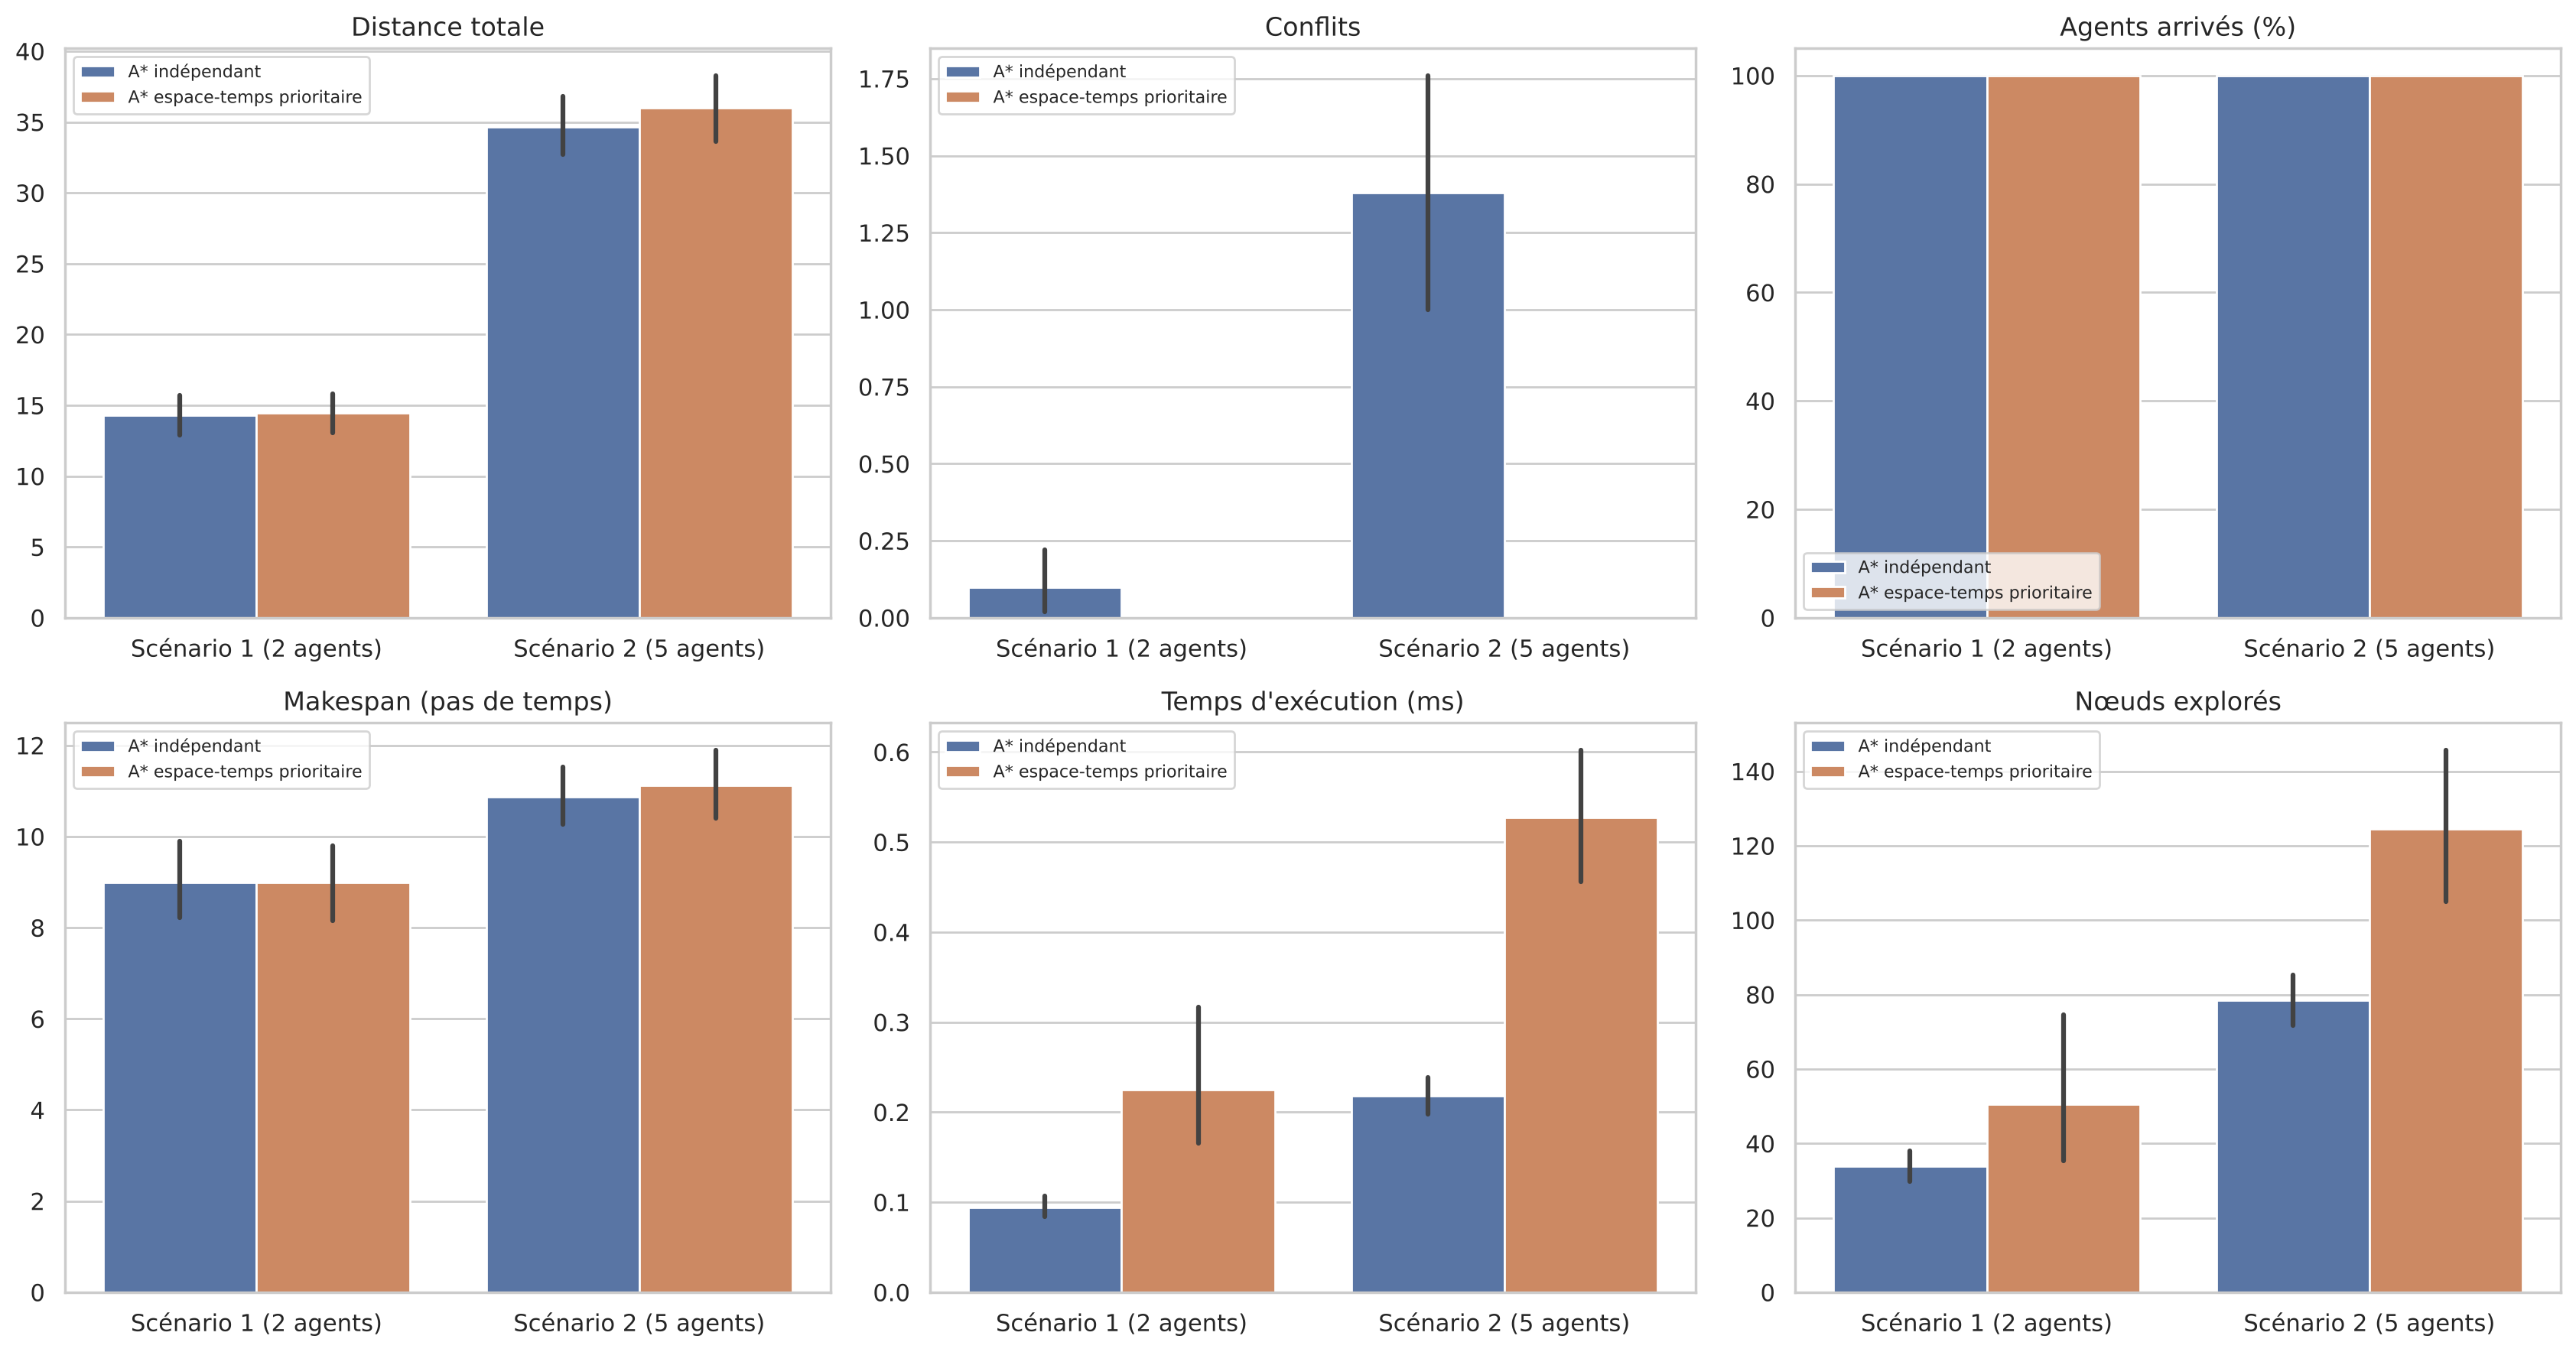

In [4]:
labels = {"total_distance": "Distance totale", "n_conflicts": "Conflits",
          "success_rate": "Agents arrivés (%)", "makespan": "Makespan (pas de temps)",
          "runtime_ms": "Temps d'exécution (ms)", "nodes_expanded": "Nœuds explorés"}
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (metric, label) in zip(axes.flat, labels.items()):
    sns.barplot(data=df, x="scenario", y=metric, hue="planner", ax=ax)
    ax.set_title(label); ax.set_xlabel(""); ax.set_ylabel("")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "experiments_metrics.png", dpi=120); plt.show()

### Coût de la coordination

Surcoût relatif du planificateur prioritaire par rapport à la baseline, calculé instance par instance.

In [5]:
wide = df.pivot_table(index=["scenario", "seed"], columns="planner",
                      values=["total_distance", "makespan", "runtime_ms"])
ind, pri = "A* indépendant", "A* espace-temps prioritaire"
overhead = pd.DataFrame({
    "distance_+%": 100 * (wide["total_distance"][pri] / wide["total_distance"][ind] - 1),
    "makespan_+%": 100 * (wide["makespan"][pri] / wide["makespan"][ind] - 1),
    "runtime_x": wide["runtime_ms"][pri] / wide["runtime_ms"][ind],
}).groupby("scenario").mean()
overhead

,distance_+%,makespan_+%,runtime_x
scenario,,,
Scénario 1 (2 agents),0.70,0.00,2.16
Scénario 2 (5 agents),3.65,2.01,2.43


## 4. Exemple visuel (scénario 2, graine 3)

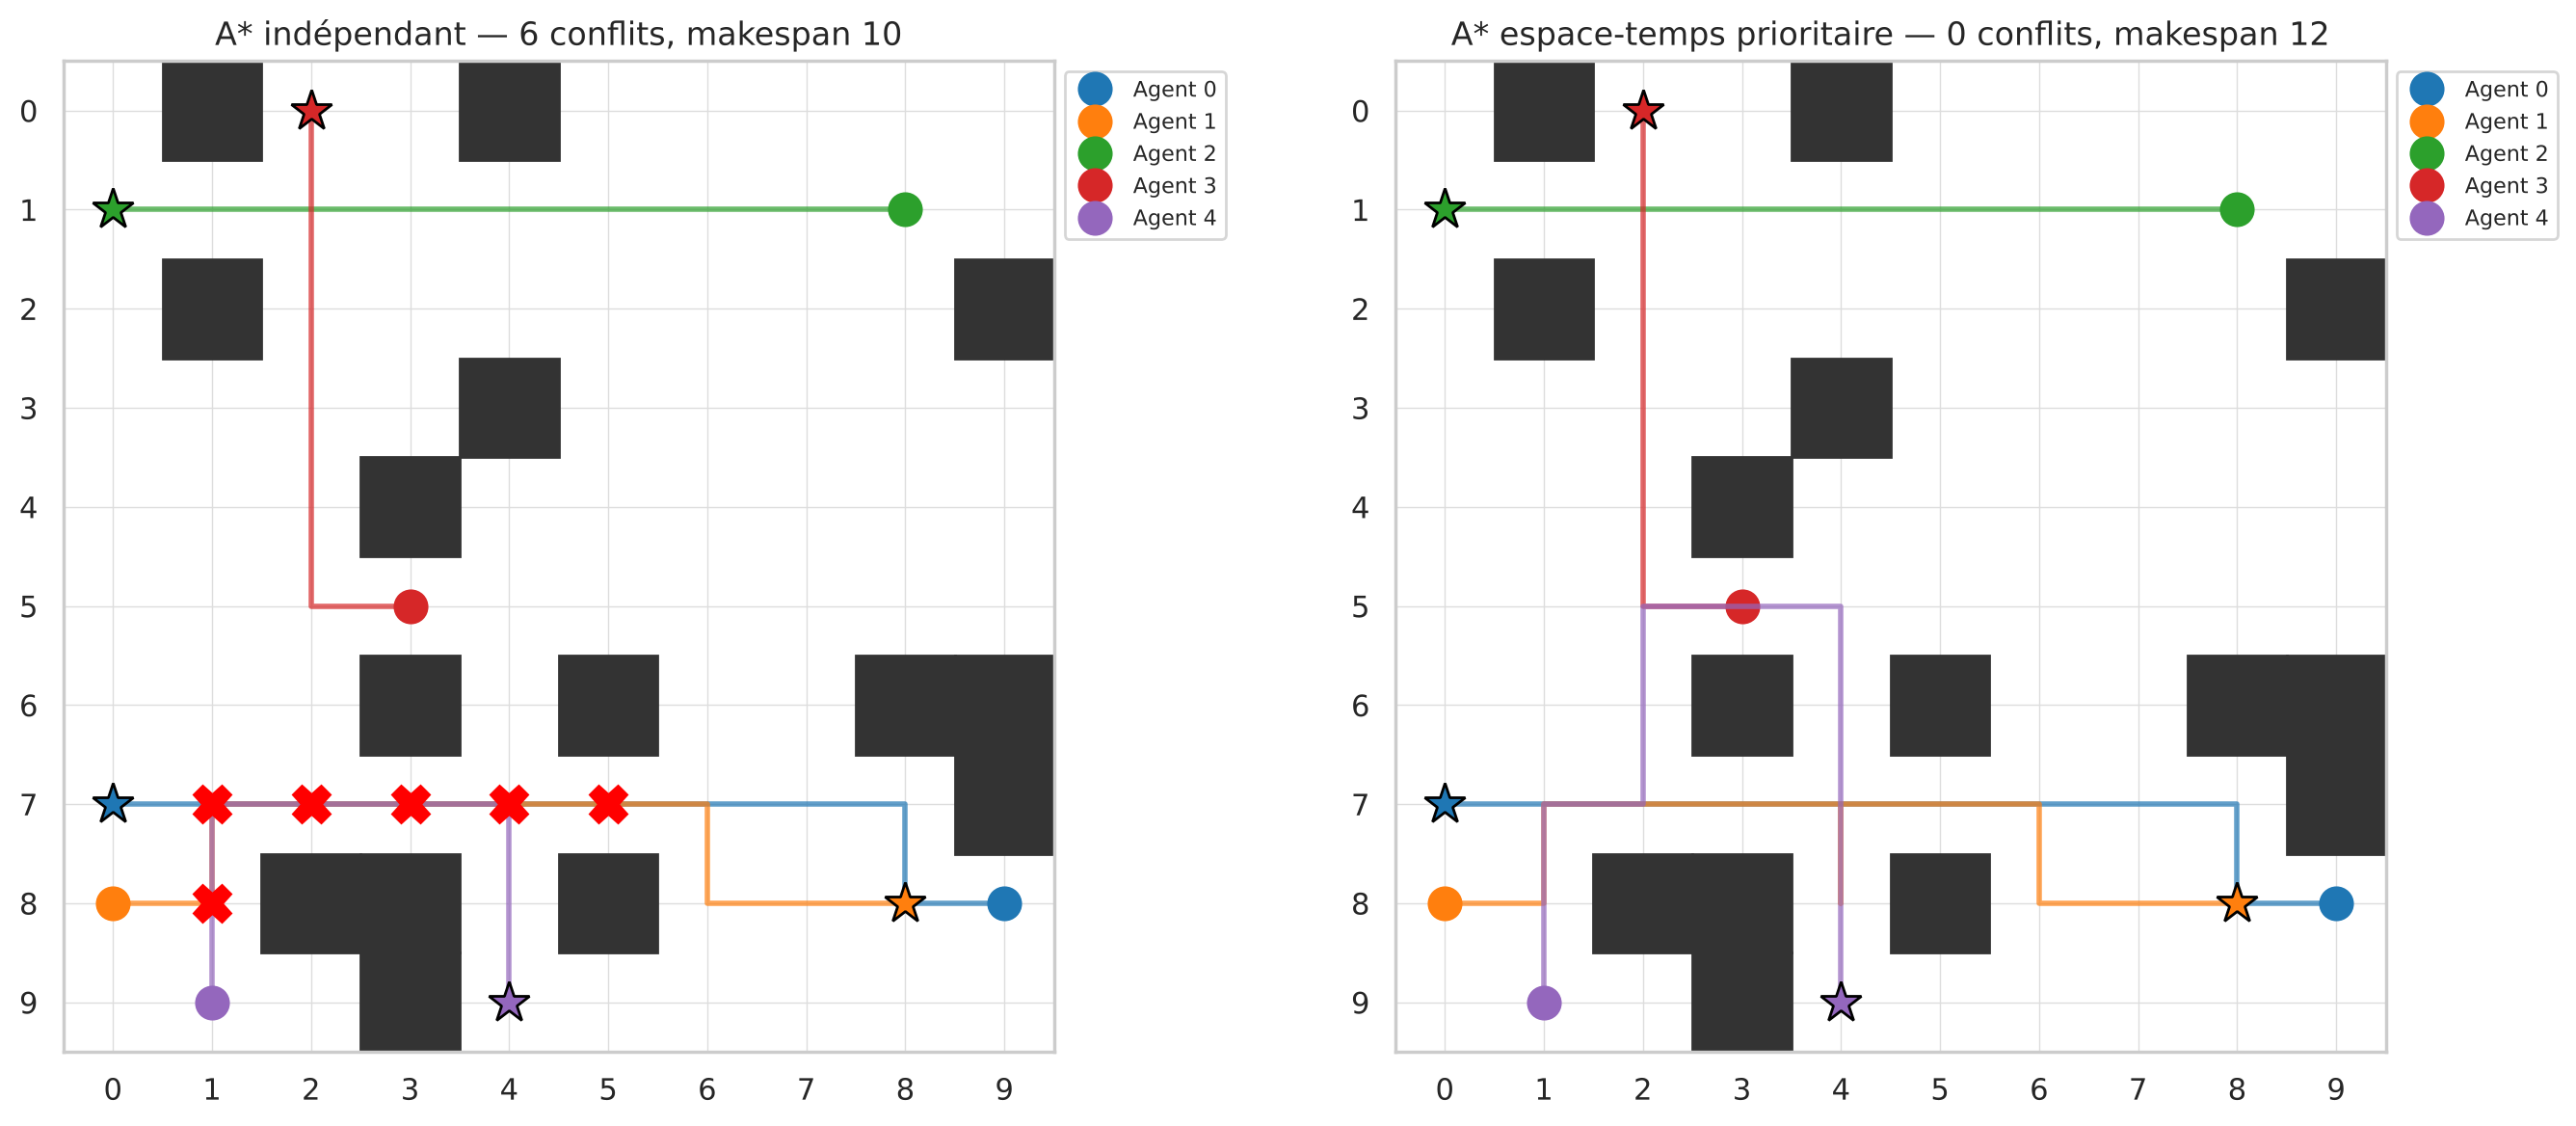

In [6]:
grid, agents = ScenarioGenerator(10, 10, 0.15, seed=3).generate(5)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, P in zip(axes, PLANNERS):
    sim = Simulation(grid, agents, P); m = sim.run()
    plot_paths(grid, sim.agents, ax, title=f"{m.planner} — {m.n_conflicts} conflits, makespan {m.makespan}")
plt.tight_layout(); plt.savefig(FIG + "experiments_example.png", dpi=120); plt.show()
animate(grid, sim.agents, FIG + "scenario2_prioritized.gif", title="Scénario 2 — prioritaire")

## 5. Passage à l'échelle (au-delà du sujet)

Pour discuter la scalabilité, on augmente le nombre d'agents sur une grille 20×20 (20 graines par point).

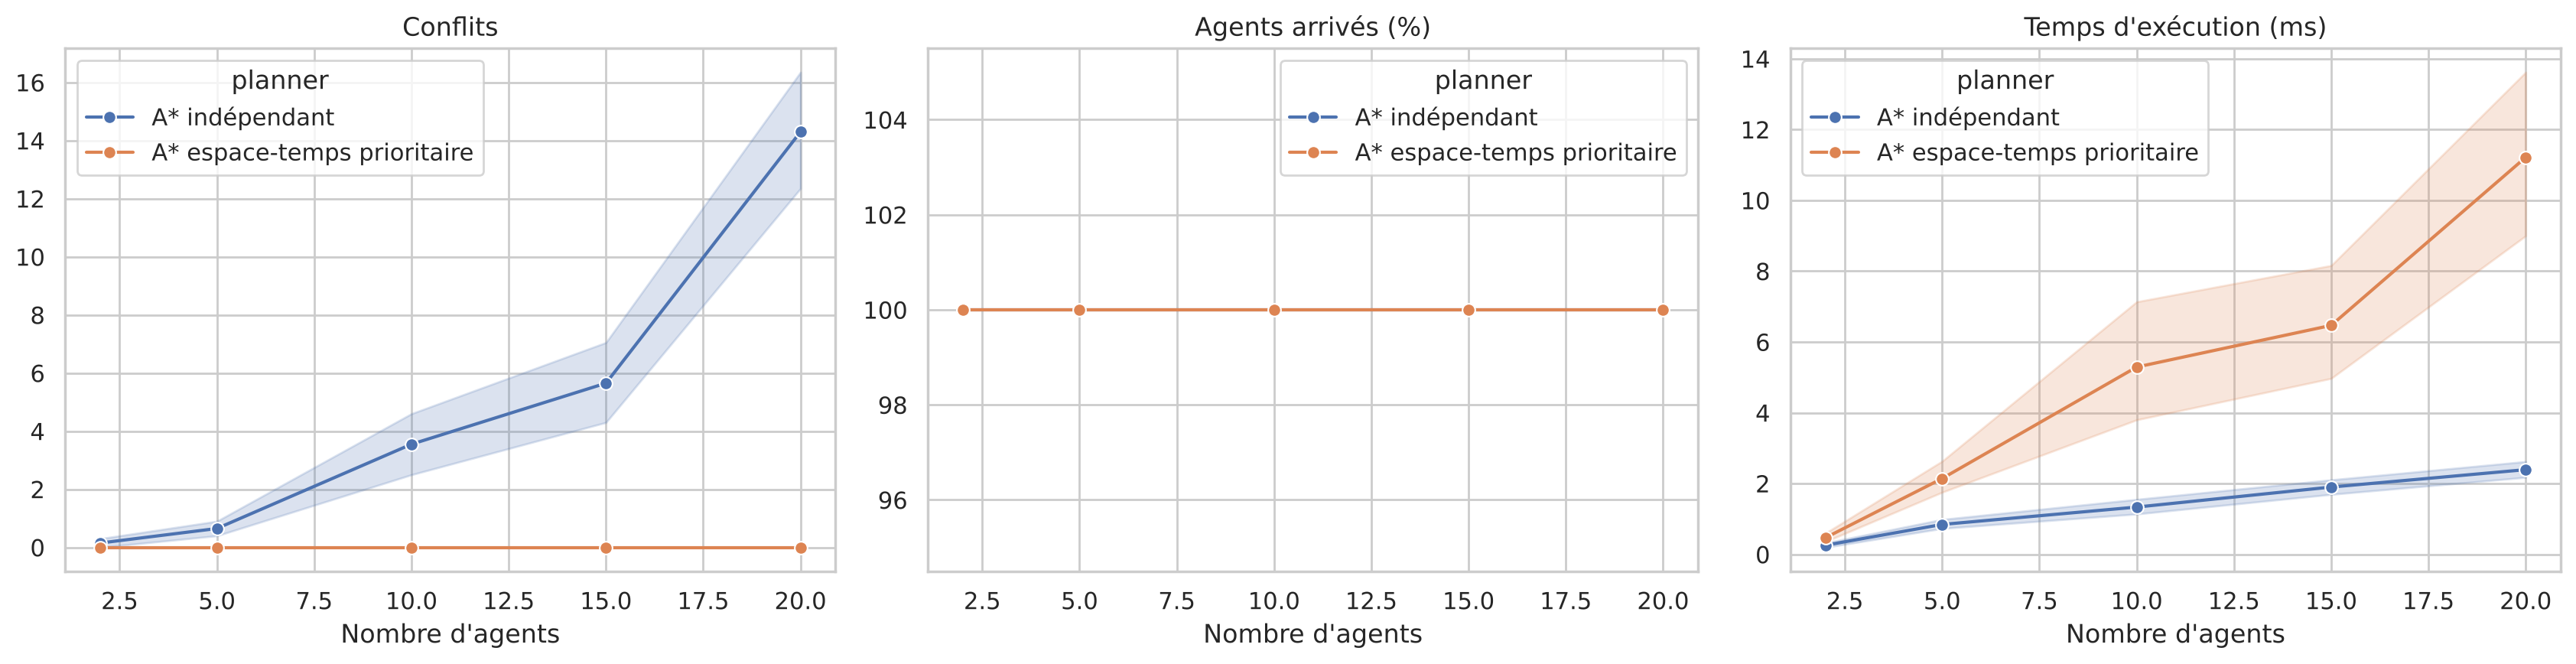

n_conflicts  success_rate  makespan  \
n_agents_cfg planner                                                            
2            A* espace-temps prioritaire         0.00         100.0     17.65   
             A* indépendant                      0.15         100.0     17.65   
5            A* espace-temps prioritaire         0.00         100.0     22.15   
             A* indépendant                      0.65         100.0     22.15   
10           A* espace-temps prioritaire         0.00         100.0     24.75   
             A* indépendant                      3.55         100.0     24.75   
15           A* espace-temps prioritaire         0.00         100.0     26.10   
             A* indépendant                      5.65         100.0     26.10   
20           A* espace-temps prioritaire         0.00         100.0     27.60   
             A* indépendant                     14.30         100.0     27.45   

                                          runtime_ms  
n_agents_cfg planner                                  
2            A* espace-temps prioritaire        0.47  
             A* indépendant                     0.26  
5            A* espace-temps prioritaire        2.14  
             A* indépendant                     0.84  
10           A* espace-temps prioritaire        5.29  
             A* indépendant                     1.33  
15           A* espace-temps prioritaire        6.47  
             A* indépendant                     1.90  
20           A* espace-temps prioritaire       11.22  
             A* indépendant                     2.39

In [7]:
scal = pd.concat([run_experiment(20, n, seeds=range(20)).assign(n_agents_cfg=n)
                  for n in [2, 5, 10, 15, 20]], ignore_index=True)
scal.to_csv(FIG + "scalability.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric, label in zip(axes, ["n_conflicts", "success_rate", "runtime_ms"],
                             ["Conflits", "Agents arrivés (%)", "Temps d'exécution (ms)"]):
    sns.lineplot(data=scal, x="n_agents_cfg", y=metric, hue="planner", marker="o", ax=ax)
    ax.set_title(label); ax.set_xlabel("Nombre d'agents"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "scalability.png", dpi=120); plt.show()
scal.groupby(["n_agents_cfg", "planner"])[["n_conflicts", "success_rate", "makespan", "runtime_ms"]].mean()

## 6. Discussion

*Brouillon à réécrire avec tes propres mots à partir des chiffres obtenus.*

**Résultats.**
- Sans coordination, les conflits sont rares à 2 agents mais fréquents à 5 agents. Le planificateur prioritaire les élimine sur les instances testées.
- Le prix de la sécurité : distance et makespan légèrement plus élevés (attentes et détours) et un temps de calcul plus grand, car la recherche se fait dans l'espace (x, y, t).
- Les temps restent de l'ordre de la milliseconde : compatibles avec une replanification en ligne pour un petit essaim.

**Limites.**
- La planification prioritaire est **incomplète** : un mauvais ordre de priorité peut bloquer un agent alors qu'une solution existe (couloirs étroits, forte densité).
- Elle n'est **pas optimale** : chaque agent minimise son propre coût, pas le coût global.
- Le modèle est simplifié : grille discrète, vitesse constante, pas de dynamique de vol, pas d'incertitude ni de 3D, communication parfaite et centralisée.

**Améliorations possibles.**
- Redémarrages avec d'autres ordres de priorité en cas d'échec.
- **CBS** (Conflict-Based Search) : complet et optimal, mais coûteux quand le nombre de conflits augmente.
- Approches décentralisées (ORCA, réservation locale) pour un vrai essaim.
- Sélection globale de chemins par **optimisation QUBO** (notebook 03) : choisir conjointement un chemin candidat par agent en minimisant coût et conflits.